# Random Forest Classification of Premier League Match Outcomes

## 1. Introduction

The research question for our group project is: **How well can we classify outcomes from Premier League matches based on models trained on the lower leagues?** This report examines six Random Forest experiments using lower-league matches for training and Premier League matches for testing. They consist of original, class-weight-balanced and GridSearchCV-tuned models in each of two feature sets: **12 full-time match statistics without Odds**, and **those same 12 statistics plus three Bet365 Odds features**.

Match results are grouped into **H** (home win), **D** (draw) and **A** (away win). Since full-time match statistics are used, this is retrospective classification of completed matches, not forecasting before kick-off. Data exploration and the four EDA figures are supplied separately in `EDA_Final_Report.ipynb`; this Notebook focuses on missing data, Random Forest implementation, six-metric evaluation, class weighting, tuning and model comparison.

## 2. Dataset

### 2.1 Data Source

The dataset contains historical English football match data from Football-Data.co.uk. The processed data was divided into two datasets based on football league divisions.

**Training Dataset:**
- Championship (E1)
- League One (E2)
- League Two (E3)

**Test Dataset:**
- Premier League (E0)

| Dataset | Number of Matches |
|---|---:|
| Lower-league training data | 37,824 |
| Premier League test data | 8,740 |

The models were trained using lower-league matches and evaluated using Premier League matches. This design allows us to investigate whether relationships learned from lower-league football can generalise to the Premier League.

### 2.2 Input Features

The baseline Random Forest model uses 12 full-time match statistics:

| Feature | Description |
|---|---|
| HS | Home team shots |
| AS | Away team shots |
| HST | Home team shots on target |
| AST | Away team shots on target |
| HF | Home team fouls |
| AF | Away team fouls |
| HC | Home team corners |
| AC | Away team corners |
| HY | Home team yellow cards |
| AY | Away team yellow cards |
| HR | Home team red cards |
| AR | Away team red cards |

The second model also includes the following betting odds:

- B365H: Home win odds
- B365D: Draw odds
- B365A: Away win odds

The target variable is **FTR (Full-Time Result)**. Full-time goals (FTHG and FTAG) are excluded from the predictors because they directly determine the match result.

## 3. Data Loading and Preparation

The processed dataset was prepared by a group member and divided according to football league divisions. The training dataset contains matches from the Championship, League One and League Two, while the test dataset contains Premier League matches. We load the two datasets separately to ensure that Premier League matches are not used to train the model.

In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Find the processed data folder
def find_data_folder():
    candidates = [
        Path.cwd() / "processed-data",
        Path.cwd().parent / "processed-data",
        Path.cwd().parent.parent / "processed-data"
    ]

    for folder in candidates:
        if (
            (folder / "football_train_data.csv").exists()
            and (folder / "football_test_data.csv").exists()
        ):
            return folder

    raise FileNotFoundError(
        "Cannot find the processed-data folder. "
        "Check the notebook's working directory."
    )

data_folder = find_data_folder()

# Load the datasets
train_data = pd.read_csv(
    data_folder / "football_train_data.csv"
)

test_data = pd.read_csv(
    data_folder / "football_test_data.csv"
)

print("Training dataset:", train_data.shape)
print("Premier League test dataset:", test_data.shape)

display(train_data.head())


Training dataset: (37824, 90)
Premier League test dataset: (8740, 90)


,FTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,...,BFDA,BMGMH,BMGMD,BMGMA,BVH,BVD,BVA,CLH,CLD,CLA
0,D,16.0,5.0,9.0,3.0,7.0,14.0,8.0,5.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A,7.0,6.0,2.0,2.0,15.0,17.0,6.0,1.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A,13.0,11.0,5.0,7.0,11.0,19.0,6.0,5.0,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,D,13.0,7.0,4.0,4.0,8.0,20.0,2.0,6.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,H,10.0,11.0,4.0,8.0,17.0,20.0,4.0,6.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:

# Check target variable
print("Training outcome distribution:")
print(train_data["FTR"].value_counts())

print("\nPremier League outcome distribution:")
print(test_data["FTR"].value_counts())

# Compare outcome percentages
outcome_comparison = pd.DataFrame({
    "Lower leagues (%)": (
        train_data["FTR"]
        .value_counts(normalize=True) * 100
    ),
    "Premier League (%)": (
        test_data["FTR"]
        .value_counts(normalize=True) * 100
    )
}).round(2)

display(outcome_comparison)

# Check missing values
print("\nMissing values in training dataset:")
display(
    train_data.isna().sum().loc[
        lambda x: x > 0
    ]
)


Training outcome distribution:
FTR
H    16298
A    11306
D    10220
Name: count, dtype: int64

Premier League outcome distribution:
FTR
H    3976
A    2605
D    2159
Name: count, dtype: int64


,Lower leagues (%),Premier League (%)
FTR,,
H,43.09,45.49
A,29.89,29.81
D,27.02,24.70



Missing values in training dataset:


HS         1
AS         1
HST        1
AST        1
HF         3
       ...  
BVD    36168
BVA    36168
CLH    36650
CLD    36650
CLA    36650
Length: 89, dtype: int64

## 4. Missing Data Analysis

### 4.1 Identifying Missing Values

Before training the Random Forest models, missing values were examined in the selected predictors. The baseline model uses 12 full-time match statistics. Only three training observations contained missing values among these features. Because the number of affected observations was very small compared with the full training dataset, several missing-data handling methods were investigated.

### 4.2 Missing Data Handling Methods

Five approaches were considered:

1. **Complete-case Analysis:** Removes observations containing missing values.
2. **Available-case Analysis:** Uses available observations for descriptive statistical calculations.
3. **Mean Imputation:** Replaces missing values with the mean of each feature.
4. **Regression Imputation:** Estimates missing values using relationships between variables.
5. **Multiple Imputation:** Generates multiple completed datasets to account for uncertainty in missing values.

Available-case analysis was used for descriptive analysis rather than as a separate Random Forest model.

### 4.3 Comparison of Methods

Four methods were compared using Random Forest classification.

| Method | Accuracy | Macro F1 | Draw Recall |
|---|---:|---:|---:|
| Complete-case | 57.21% | 45.76% | 6.21% |
| Mean Imputation | 56.97% | 45.57% | 6.25% |
| Regression Imputation | 56.99% | 45.54% | 6.07% |
| Multiple Imputation | 57.16% | 45.61% | 5.93% |

Complete-case analysis achieved the highest overall accuracy and Macro F1-score, although the differences between methods were small. Therefore, complete-case analysis was selected for the baseline Random Forest model. This choice was appropriate for the current dataset because only three training observations were affected. However, it does not mean that complete-case analysis is always better than imputation.

In [18]:

# Selected features for the baseline Random Forest
features = [
    "HS", "AS", "HST", "AST",
    "HF", "AF", "HC", "AC",
    "HY", "AY", "HR", "AR"
]

# Missing values in the selected features
missing_summary = pd.DataFrame({
    "Training Missing": train_data[features].isna().sum(),
    "Test Missing": test_data[features].isna().sum()
})

display(missing_summary)

# Number of observations containing missing features
train_missing_rows = train_data[features].isna().any(axis=1).sum()
test_missing_rows = test_data[features].isna().any(axis=1).sum()

print("Training rows with missing features:", train_missing_rows)
print("Test rows with missing features:", test_missing_rows)

# Complete-case dataset
train_clean = train_data.dropna(
    subset=features + ["FTR"]
).copy()

test_clean = test_data.dropna(
    subset=features + ["FTR"]
).copy()

print("Clean training dataset:", train_clean.shape)
print("Clean test dataset:", test_clean.shape)


,Training Missing,Test Missing
HS,1,0
AS,1,0
HST,1,0
AST,1,0
HF,3,0
AF,3,0
HC,1,0
AC,1,0
HY,1,0
AY,1,0


Training rows with missing features: 3
Test rows with missing features: 0
Clean training dataset: (37821, 90)
Clean test dataset: (8740, 90)


**Table interpretation — missing values.** This table counts missing values in each of the 12 full-time match-statistic predictors. Three lower-league training matches have at least one missing predictor, while none of the Premier League test matches has a missing value in these predictors. Complete-case filtering therefore leaves **37,821 training matches** and **8,740 test matches**. The report applies this cleaning only to the specified predictors and target, not to every column in the original dataset.

## 5. Random Forest Model

### 5.1 Model Implementation

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve classification performance. The baseline Random Forest model uses 12 full-time match statistics to classify match outcomes into home wins, draws and away wins. The model is trained on Championship, League One and League Two matches and evaluated on Premier League matches. The following hyperparameters are used:

| Hyperparameter | Value |
|---|---|
| Number of trees (`n_estimators`) | 200 |
| Maximum depth (`max_depth`) | 12 |
| Random state | 42 |
| Parallel processing (`n_jobs`) | -1 |

These parameters are kept consistent with the original Random Forest experiment.

These settings were used for the original Random Forest model. Hyperparameter tuning was carried out later, and the results are discussed in Section 8.1.

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Prepare training and testing features
X_train_clean = train_clean[features]
y_train_clean = train_clean["FTR"]

X_test = test_clean[features]
y_test = test_clean["FTR"]

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# Train on lower-league matches
model.fit(X_train_clean, y_train_clean)

# Predict Premier League match outcomes
y_pred = model.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, log_loss)
from IPython.display import display
import pandas as pd

def six_metric_summary(fitted_model, X, y):
    """Six comparable metrics for one fitted model on the specified test set."""
    pred = fitted_model.predict(X)
    proba = fitted_model.predict_proba(X)
    return {
        "Accuracy (%)": accuracy_score(y, pred) * 100,
        "Macro Precision (%)": precision_score(y, pred, average="macro", zero_division=0) * 100,
        "Macro Recall (%)": recall_score(y, pred, average="macro", zero_division=0) * 100,
        "Macro F1 (%)": f1_score(y, pred, average="macro", zero_division=0) * 100,
        "Multiclass ROC-AUC": roc_auc_score(y, proba, labels=fitted_model.classes_,
                                              multi_class="ovr", average="macro"),
        "Multiclass Log Loss": log_loss(y, proba, labels=fitted_model.classes_)
    }

def show_six_metrics(model_name, fitted_model, X, y):
    metrics = six_metric_summary(fitted_model, X, y)
    display(pd.DataFrame({"Metric": list(metrics), model_name: list(metrics.values())}).round(4))
    return metrics

show_six_metrics("Original RF (12 features)", model, X_test, y_test)


**Six-metric interpretation — Original RF (without Odds).** Accuracy is **57.21%**, meaning around 57 of every 100 Premier League matches are classified correctly. Macro F1 is **45.76%**, showing weaker average performance when home wins, draws and away wins are given equal importance. Multiclass ROC-AUC is **0.7134** and Log Loss is **0.9240**; these assess class separation and probability quality respectively. Macro Precision and Macro Recall are also calculated in the table rather than inferred from accuracy.

### 5.2 Training and Test Performance

To investigate how well the Random Forest model generalises across football leagues, its classification performance is compared between the lower-league training dataset and the Premier League test dataset. The training accuracy shows how well the model classifies the data used for fitting, while the test accuracy measures performance on Premier League matches that were not used during training. A difference between training and test accuracy may reflect overfitting, differences in match characteristics, or differences in the distribution of match outcomes across leagues. Both accuracy and Macro F1-score are reported because the model has difficulty identifying drawn matches.

In [20]:

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Predictions on lower-league training data
train_pred = model.predict(X_train_clean)

# Predictions on Premier League test data
test_pred = model.predict(X_test)

# Compare performance
performance_comparison = pd.DataFrame({
    "Dataset": [
        "Lower-league Training",
        "Premier League Testing"
    ],
    "Accuracy": [
        accuracy_score(y_train_clean, train_pred),
        accuracy_score(y_test, test_pred)
    ],
    "Macro F1": [
        f1_score(y_train_clean, train_pred, average="macro"),
        f1_score(y_test, test_pred, average="macro")
    ]
})

display(performance_comparison.round(4))

accuracy_gap = (
    performance_comparison.loc[0, "Accuracy"]
    - performance_comparison.loc[1, "Accuracy"]
)

print(f"Training - Test Accuracy Gap: {accuracy_gap:.4f}")


,Dataset,Accuracy,Macro F1
0,Lower-league Training,0.6620,0.6101
1,Premier League Testing,0.5721,0.4576


Training - Test Accuracy Gap: 0.0899


### 5.3 Confusion Matrix

A confusion matrix is used to examine how well the Random Forest model identifies home wins, draws and away wins. It provides more information than overall accuracy because it shows which outcome categories are frequently misclassified. This is particularly important for drawn matches, which the model has difficulty identifying.

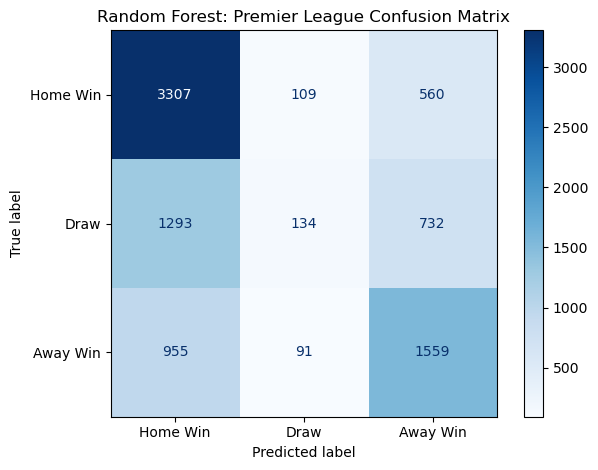

Classification Report:
              precision    recall  f1-score   support

    Home Win       0.60      0.83      0.69      3976
        Draw       0.40      0.06      0.11      2159
    Away Win       0.55      0.60      0.57      2605

    accuracy                           0.57      8740
   macro avg       0.51      0.50      0.46      8740
weighted avg       0.53      0.57      0.51      8740



In [21]:

import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report
)

labels = ["H", "D", "A"]

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Home Win", "Draw", "Away Win"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest: Premier League Confusion Matrix")
plt.tight_layout()
plt.show()

print("Classification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        labels=labels,
        target_names=["Home Win", "Draw", "Away Win"],
        zero_division=0
    )
)


**Figure interpretation — Original RF confusion matrix.** Rows are the actual match outcomes and columns are model classifications; diagonal cells are correct. The model identifies many home wins and away wins but misses most draws. Draw Recall is only **6.21%**, so a reasonable overall Accuracy does not mean it works equally well for all three outcomes.

### 5.4 Handling Class Imbalance

The baseline Random Forest model has difficulty identifying drawn matches, with a draw recall of only 6.21%. To investigate this problem, we examine the distribution of home wins, draws and away wins in the training dataset. We then compare the original Random Forest with a class-weighted Random Forest using `class_weight="balanced"`. This method gives greater importance to less frequent classes during model training without changing the Premier League test dataset.

In [22]:

# Check class distribution
class_distribution = pd.DataFrame({
    "Count": y_train_clean.value_counts(),
    "Percentage (%)": (
        y_train_clean.value_counts(normalize=True) * 100
    ).round(2)
})

display(class_distribution)


,Count,Percentage (%)
FTR,,
H,16296,43.09
A,11305,29.89
D,10220,27.02


In [23]:


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score
)
import pandas as pd

# Random Forest with balanced class weights
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train on lower-league data only
rf_balanced.fit(X_train_clean, y_train_clean)

# Predict Premier League outcomes
y_pred_balanced = rf_balanced.predict(X_test)

# Compare the original and balanced models
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Draw Precision": precision_score(
            y_true == "D", y_pred == "D",
            zero_division=0
        ),
        "Draw Recall": recall_score(
            y_true == "D", y_pred == "D",
            zero_division=0
        ),
        "Draw F1": f1_score(
            y_true == "D", y_pred == "D",
            zero_division=0
        )
    }

comparison = pd.DataFrame({
    "Original RF": evaluate_model(y_test, y_pred),
    "Balanced RF": evaluate_model(y_test, y_pred_balanced)
}).T

display((comparison * 100).round(2))


,Accuracy,Macro F1,Draw Precision,Draw Recall,Draw F1
Original RF,57.21,45.76,40.12,6.21,10.75
Balanced RF,55.76,50.24,32.79,20.52,25.24


### Six Evaluation Metrics — Balanced RF (Without Odds)

These metrics use the same Premier League test set as the original 12-feature model. They are calculated separately for the balanced model, not copied from the original model.

In [ ]:
balanced_six = show_six_metrics("Balanced RF (12 features)", rf_balanced, X_test, y_test)

**Interpretation.** With balanced class weights, Accuracy falls to **55.76%** but Macro F1 rises to **50.24%**. Draw Recall improves from **6.21% to 20.52%**. This is a trade-off: better recognition of less frequent outcomes, but slightly fewer correct classifications overall. The table gives the remaining precision, recall, ROC-AUC and Log Loss values.

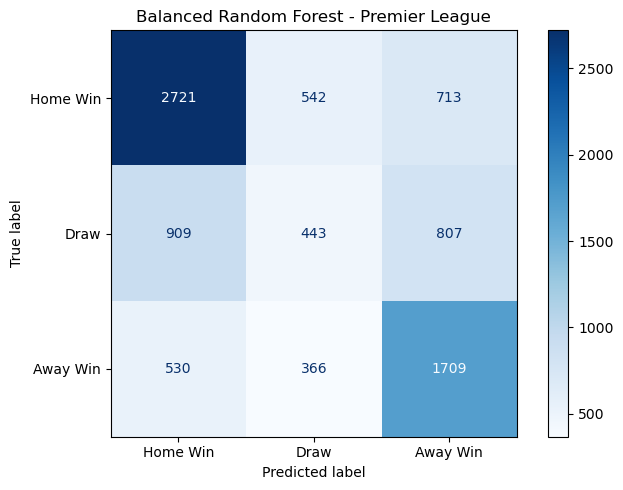

In [24]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced,
    labels=["H", "D", "A"],
    display_labels=["Home Win", "Draw", "Away Win"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Balanced Random Forest - Premier League")
plt.tight_layout()
plt.show()


**Figure interpretation — Balanced RF confusion matrix.** The diagonal cell for Draw contains **443** correctly classified drawn matches. This is an improvement over the original model, although many actual draws remain in the Home Win and Away Win columns. Balanced class weighting improves draw sensitivity but does not remove the confusion between categories.

### 5.5 Evaluation of Class Weight Balancing

To address the low recall for drawn matches, a second Random Forest was trained using `class_weight="balanced"`. This approach adjusts the importance of each class according to its frequency in the training data. The balanced model was evaluated against the original Random Forest using Accuracy, Macro F1, Draw Precision, Draw Recall and Draw F1. The main objective was to investigate whether class weighting could improve the identification of drawn matches and how this affected overall classification performance. The results are presented above. Improvements in draw recall must be considered alongside changes in precision, Macro F1 and overall accuracy.

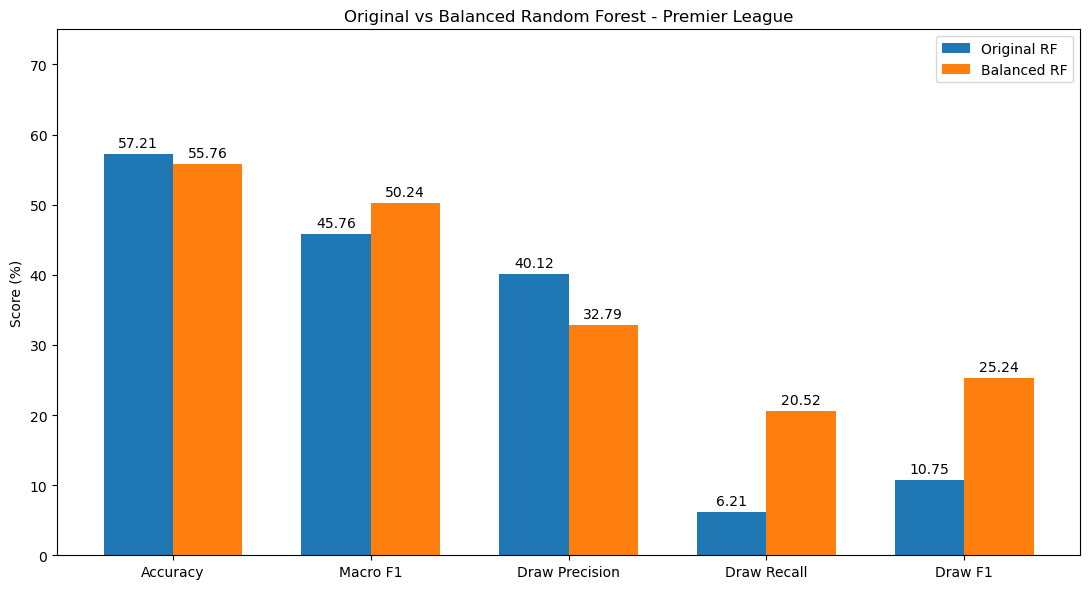

In [25]:

import numpy as np
import matplotlib.pyplot as plt

# Use the comparison table calculated earlier
metrics = [
    "Accuracy",
    "Macro F1",
    "Draw Precision",
    "Draw Recall",
    "Draw F1"
]

original = comparison.loc["Original RF", metrics].to_numpy() * 100
balanced = comparison.loc["Balanced RF", metrics].to_numpy() * 100

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    original,
    width,
    label="Original RF"
)

bars2 = ax.bar(
    x + width / 2,
    balanced,
    width,
    label="Balanced RF"
)

ax.set_ylabel("Score (%)")
ax.set_title(
    "Original vs Balanced Random Forest - Premier League"
)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 75)
ax.legend()

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


### Comparison of Original and Balanced Random Forest

The figure compares classification performance before and after applying class weighting. Draw recall increased from **6.21% to 20.52%**, while draw F1-score improved from **10.75% to 25.24%**. Macro F1-score also increased from **45.76% to 50.24%**, suggesting improved performance across the three outcome categories. However, overall accuracy decreased from **57.21% to 55.76%**, and draw precision decreased from **40.12% to 32.79%**. This demonstrates a precision–recall trade-off: the balanced model identifies more actual draws but also incorrectly predicts more draws. Although class weighting improved draw classification, its recall remained relatively low at 20.52%, indicating that further improvements are needed.

### 5.6 Hyperparameter Tuning (Without Odds)

This code was integrated from `BingquanW/04_RandomForest/RandomForest.ipynb`. GridSearchCV uses **only the lower-league training set** for three-fold stratified cross-validation and selects parameters by **Macro F1**. The Premier League data are used only for final testing. The displayed results are from the supplied notebook; rerunning all cells will recompute them.

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from IPython.display import display as show_table
import pandas as pd

# Parameters to compare
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [1, 3],
    "class_weight": [None, "balanced"]
}

# Cross-validation within lower-league training data
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train_clean, y_train_clean)

print("Best parameters:")
print(grid_search.best_params_)

print("Best cross-validation Macro F1:")
print(round(grid_search.best_score_, 4))

# Show the best parameter combinations
tuning_results = pd.DataFrame(grid_search.cv_results_)

columns = [
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_leaf",
    "param_class_weight",
    "mean_test_score",
    "std_test_score"
]

show_table(
    tuning_results[columns]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
    .round(4)
)


Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best parameters:
{'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 200}
Best cross-validation Macro F1:
0.4903


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score
19,200,12,3,balanced,0.4903,0.0023
18,100,12,3,balanced,0.4902,0.0024
17,200,12,1,balanced,0.4889,0.0022
16,100,12,1,balanced,0.4883,0.0017
12,100,8,1,balanced,0.4875,0.0020
15,200,8,3,balanced,0.4869,0.0031
23,200,16,3,balanced,0.4868,0.0016
13,200,8,1,balanced,0.4856,0.0017
22,100,16,3,balanced,0.4852,0.0019
14,100,8,3,balanced,0.4848,0.0024


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss
)
import pandas as pd
from IPython.display import display as show_table

# Best model selected by GridSearchCV
best_rf = grid_search.best_estimator_

# Evaluate on Premier League test data
y_pred_tuned = best_rf.predict(X_test)
y_proba_tuned = best_rf.predict_proba(X_test)

tuned_metrics = {
    "Accuracy (%)": accuracy_score(y_test, y_pred_tuned) * 100,
    "Macro Precision (%)": precision_score(
        y_test, y_pred_tuned, average="macro", zero_division=0
    ) * 100,
    "Macro Recall (%)": recall_score(
        y_test, y_pred_tuned, average="macro", zero_division=0
    ) * 100,
    "Macro F1 (%)": f1_score(
        y_test, y_pred_tuned, average="macro", zero_division=0
    ) * 100,
    "Multiclass ROC-AUC": roc_auc_score(
        y_test, y_proba_tuned,
        labels=best_rf.classes_,
        multi_class="ovr",
        average="macro"
    ),
    "Multiclass Log Loss": log_loss(
        y_test, y_proba_tuned, labels=best_rf.classes_
    )
}

show_table(
    pd.DataFrame({
        "Metric": list(tuned_metrics.keys()),
        "Tuned RF": list(tuned_metrics.values())
    }).round(4)
)


,Metric,Tuned RF
0,Accuracy (%),55.8696
1,Macro Precision (%),50.6466
2,Macro Recall (%),51.7305
3,Macro F1 (%),50.4686
4,Multiclass ROC-AUC,0.7140
5,Multiclass Log Loss,0.9432


**Six-metric interpretation — Tuned RF (without Odds).** GridSearchCV selects hyperparameters using three-fold cross-validation on the lower-league training matches, optimising Macro F1. On the held-out Premier League data, the tuned model obtains **55.87% Accuracy** and **50.47% Macro F1**. The latter is slightly higher than the balanced-only model (**50.24%**), but Accuracy remains below the original RF (**57.21%**). This is an improvement for the selected Macro F1 objective, not an improvement on every metric.

### 5.7 Original, Balanced and Tuned RF Comparison (Without Odds)

The table gives overall and draw-specific test metrics for all three 12-feature models. Class weighting primarily improves draw detection; the additional GridSearchCV gain in Macro F1 is small.

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, log_loss
)
import pandas as pd
from IPython.display import display as show_table

models = {
    "Original RF": model,
    "Balanced RF": rf_balanced,
    "Tuned RF": grid_search.best_estimator_
}

rows = []

for name, clf in models.items():
    pred = clf.predict(X_test)
    proba = clf.predict_proba(X_test)

    rows.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_test, pred) * 100,
        "Macro Precision (%)": precision_score(
            y_test, pred, average="macro", zero_division=0
        ) * 100,
        "Macro Recall (%)": recall_score(
            y_test, pred, average="macro", zero_division=0
        ) * 100,
        "Macro F1 (%)": f1_score(
            y_test, pred, average="macro", zero_division=0
        ) * 100,
        "Draw Precision (%)": precision_score(
            y_test == "D", pred == "D", zero_division=0
        ) * 100,
        "Draw Recall (%)": recall_score(
            y_test == "D", pred == "D", zero_division=0
        ) * 100,
        "Draw F1 (%)": f1_score(
            y_test == "D", pred == "D", zero_division=0
        ) * 100,
        "ROC-AUC": roc_auc_score(
            y_test, proba, labels=clf.classes_,
            multi_class="ovr", average="macro"
        ),
        "Log Loss": log_loss(
            y_test, proba, labels=clf.classes_
        )
    })

three_model_comparison = pd.DataFrame(rows).set_index("Model")
show_table(three_model_comparison.round(4))


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Draw Precision (%),Draw Recall (%),Draw F1 (%),ROC-AUC,Log Loss
Model,,,,,,,,,
Original RF,57.2082,51.4448,49.7424,45.7643,40.1198,6.2066,10.7501,0.7134,0.9240
Balanced RF,55.7551,50.3753,51.5197,50.2392,32.7905,20.5188,25.2422,0.7128,0.9432
Tuned RF,55.8696,50.6466,51.7305,50.4686,33.4311,21.1209,25.8870,0.7140,0.9432


## 6. Random Forest with Betting Odds

### 6.1 Model Description

The second Random Forest model includes three additional Bet365 betting odds features alongside the original 12 full-time match statistics. The additional features are:

- **B365H:** Bet365 home win odds
- **B365D:** Bet365 draw odds
- **B365A:** Bet365 away win odds

The purpose of adding betting odds is to investigate whether information from the betting market improves the classification of Premier League match outcomes. The same Random Forest hyperparameters are used to allow a direct comparison with the baseline model:

- `n_estimators = 200`
- `max_depth = 12`
- `random_state = 42`
- `n_jobs = -1`

The model is trained on Championship, League One and League Two matches and evaluated on Premier League matches. Since this model also includes full-time match statistics, it remains a retrospective classification model rather than a genuine pre-match forecasting model.

In [26]:

# Original 12 match statistics + 3 betting odds
odds_features = features + ["B365H", "B365D", "B365A"]

# Remove rows missing any required predictor or target
train_odds_clean = train_data.dropna(
    subset=odds_features + ["FTR"]
).copy()

test_odds_clean = test_data.dropna(
    subset=odds_features + ["FTR"]
).copy()

# Prepare training and test datasets
X_train_odds = train_odds_clean[odds_features]
y_train_odds = train_odds_clean["FTR"]

X_test_odds = test_odds_clean[odds_features]
y_test_odds = test_odds_clean["FTR"]

print("Number of features:", len(odds_features))
print("Odds model training rows:", len(X_train_odds))
print("Odds model test rows:", len(X_test_odds))
print("Removed training rows:", len(train_data) - len(train_odds_clean))
print("Removed test rows:", len(test_data) - len(test_odds_clean))


Number of features: 15
Odds model training rows: 37812
Odds model test rows: 8740
Removed training rows: 12
Removed test rows: 0


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Create Random Forest with betting odds
rf_odds = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# Train on lower-league matches
rf_odds.fit(X_train_odds, y_train_odds)

# Predict Premier League outcomes
y_pred_odds = rf_odds.predict(X_test_odds)

# Evaluate the model
odds_accuracy = accuracy_score(y_test_odds, y_pred_odds)
odds_macro_f1 = f1_score(
    y_test_odds,
    y_pred_odds,
    average="macro"
)

show_six_metrics("Original RF with Odds (15 features)", rf_odds, X_test_odds, y_test_odds)


**Six-metric interpretation — Original RF with Odds.** Adding Bet365 odds to the 12 match statistics increases Accuracy from **57.21% to 59.61%** (**+2.40 percentage points**), and Macro F1 from **45.76% to 47.41%**. ROC-AUC rises from **0.7134 to 0.7419** and Log Loss falls from **0.9240 to 0.8839**, suggesting better discrimination and probability quality. However, Draw Recall falls to **5.14%**; Odds do not solve the draw classification problem.

In [28]:

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest (12 features)",
        "Random Forest with Odds (15 features)"
    ],
    "Accuracy (%)": [
        accuracy * 100,
        odds_accuracy * 100
    ],
    "Macro F1 (%)": [
        macro_f1 * 100,
        odds_macro_f1 * 100
    ]
})

display(model_comparison.round(2))


,Model,Accuracy (%),Macro F1 (%)
0,Random Forest (12 features),57.21,45.76
1,Random Forest with Odds (15 features),59.61,47.41


### 6.2 Probability-Based Model Evaluation

In addition to accuracy and Macro F1-score, the models are evaluated using multiclass ROC-AUC and Log Loss. Multiclass ROC-AUC measures how well the models distinguish between home wins, draws and away wins based on predicted probabilities. Log Loss evaluates the quality of the predicted probabilities. A lower Log Loss indicates better probabilistic performance. These metrics provide additional information beyond classification accuracy.

In [29]:

from sklearn.metrics import roc_auc_score, log_loss

# Predict probabilities for both models
baseline_proba = model.predict_proba(X_test)
odds_proba = rf_odds.predict_proba(X_test_odds)

# Multiclass ROC-AUC
baseline_auc = roc_auc_score(
    y_test,
    baseline_proba,
    labels=model.classes_,
    multi_class="ovr",
    average="macro"
)

odds_auc = roc_auc_score(
    y_test_odds,
    odds_proba,
    labels=rf_odds.classes_,
    multi_class="ovr",
    average="macro"
)

# Multiclass Log Loss
baseline_logloss = log_loss(
    y_test,
    baseline_proba,
    labels=model.classes_
)

odds_logloss = log_loss(
    y_test_odds,
    odds_proba,
    labels=rf_odds.classes_
)

# Comparison table
probability_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Random Forest + Odds"
    ],
    "Multiclass ROC-AUC": [
        baseline_auc,
        odds_auc
    ],
    "Multiclass Log Loss": [
        baseline_logloss,
        odds_logloss
    ]
})

display(probability_comparison.round(4))


,Model,Multiclass ROC-AUC,Multiclass Log Loss
0,Random Forest,0.7134,0.9240
1,Random Forest + Odds,0.7419,0.8839


### 6.3 Class Weight Balancing with Odds

The odds experiment uses **15 predictors** throughout. As in the standalone Odds notebook, a second forest uses `class_weight="balanced"`. The models are both evaluated on the same Premier League test observations.

In [ ]:
# Independent odds-weighting experiment (15 predictors)
rf_odds_balanced = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight="balanced",
    random_state=42, n_jobs=-1
)
rf_odds_balanced.fit(X_train_odds, y_train_odds)
odds_balanced_pred = rf_odds_balanced.predict(X_test_odds)

from sklearn.metrics import precision_score, recall_score
odds_weight_comparison = pd.DataFrame({
    "Original Odds RF": {
        "Accuracy": accuracy_score(y_test_odds, y_pred_odds),
        "Macro F1": f1_score(y_test_odds, y_pred_odds, average="macro"),
        "Draw Precision": precision_score(y_test_odds == "D", y_pred_odds == "D", zero_division=0),
        "Draw Recall": recall_score(y_test_odds == "D", y_pred_odds == "D", zero_division=0),
        "Draw F1": f1_score(y_test_odds == "D", y_pred_odds == "D", zero_division=0)
    },
    "Balanced Odds RF": {
        "Accuracy": accuracy_score(y_test_odds, odds_balanced_pred),
        "Macro F1": f1_score(y_test_odds, odds_balanced_pred, average="macro"),
        "Draw Precision": precision_score(y_test_odds == "D", odds_balanced_pred == "D", zero_division=0),
        "Draw Recall": recall_score(y_test_odds == "D", odds_balanced_pred == "D", zero_division=0),
        "Draw F1": f1_score(y_test_odds == "D", odds_balanced_pred == "D", zero_division=0)
    }
}).T
display((odds_weight_comparison * 100).round(2))

,Accuracy,Macro F1,Draw Precision,Draw Recall,Draw F1
Original Odds RF,59.61,47.41,39.08,5.14,9.09
Balanced Odds RF,58.46,51.63,35.63,17.69,23.65


### Six Evaluation Metrics — Balanced RF with Odds

This is a separate evaluation of the balanced model using **15 features** and the same Premier League test matches as the original Odds model.

In [ ]:
balanced_odds_six = show_six_metrics("Balanced RF with Odds", rf_odds_balanced, X_test_odds, y_test_odds)

**Interpretation.** Balanced Odds RF reaches **58.46% Accuracy** and **51.63% Macro F1**. Draw Recall increases from **5.14% to 17.69%**, while Accuracy is slightly lower than the original Odds RF (**59.61%**). The six-metric table also shows how class balancing affects precision and probability-based measures.

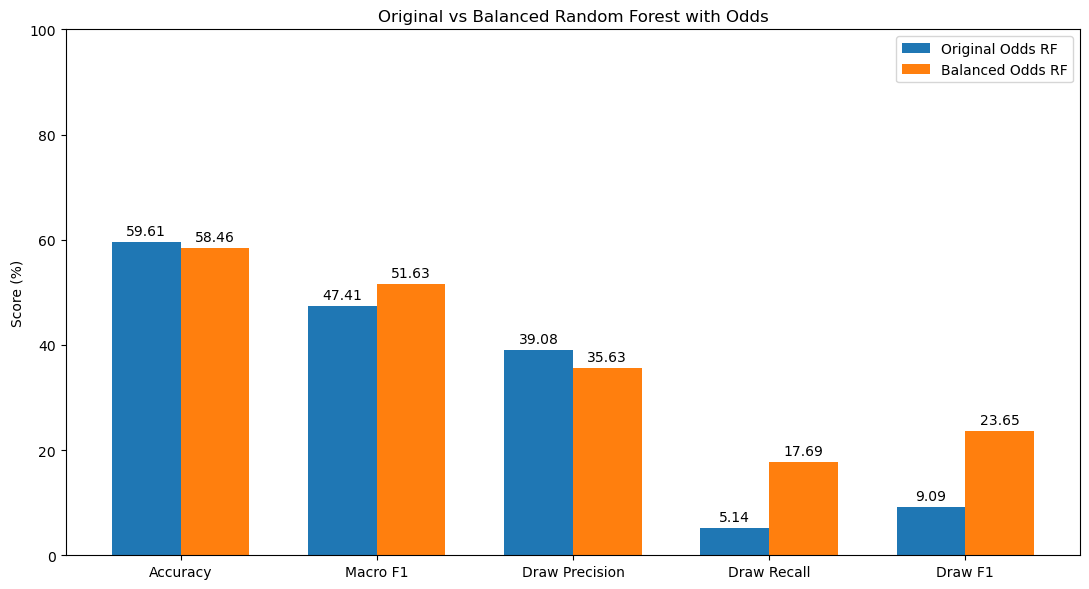

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Macro F1",
    "Draw Precision",
    "Draw Recall",
    "Draw F1"
]

# Convert scores from 0-1 to percentages
original = (
    odds_weight_comparison.loc["Original Odds RF", metrics].to_numpy()
    * 100
)

balanced = (
    odds_weight_comparison.loc["Balanced Odds RF", metrics].to_numpy()
    * 100
)

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    original,
    width,
    label="Original Odds RF"
)

bars2 = ax.bar(
    x + width / 2,
    balanced,
    width,
    label="Balanced Odds RF"
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.set_title("Original vs Balanced Random Forest with Odds")
ax.legend()

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


**Figure interpretation — Odds class-weight bar chart.** Blue bars show the original Odds model and orange bars show the class-balanced Odds model. Draw Recall increases from **5.14% to 17.69%**, Draw F1 from **9.09% to 23.65%**, and Macro F1 from **47.41% to 51.63%**. This improvement comes with lower Accuracy (**59.61% to 58.46%**) and lower Draw Precision.

**Interpretation:** Draw Recall increases from **5.14% to 17.69%**, while Macro F1 increases from **47.41% to 51.63%**. Accuracy decreases from **59.61% to 58.46%**. This is a trade-off, not an improvement on every measure.

### 6.4 GridSearchCV Tuning with Odds

The following code is integrated from `RandomForest_WithOdds.ipynb`. It uses the explicit `X_train_odds` / `y_train_odds` variables so that the 15-feature model is not confused with the 12-feature model. The reported best cross-validation Macro F1 is **0.4983**, using 24 parameter combinations and three folds.

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from IPython.display import display
import pandas as pd

# Check the 15 features used in the Odds model
print("Training features:", X_train_odds.shape[1])
print("Test features:", X_test_odds.shape[1])

assert X_train_odds.shape[1] == 15
assert X_test_odds.shape[1] == 15

# Define the hyperparameter grid
param_grid_odds = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [1, 3],
    "class_weight": [None, "balanced"]
}

# Three-fold cross-validation
cv_odds = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# GridSearchCV
odds_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=param_grid_odds,
    scoring="f1_macro",
    cv=cv_odds,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Train using lower-league data only
odds_grid_search.fit(X_train_odds, y_train_odds)

# Display the best results
print("\nBest parameters:")
print(odds_grid_search.best_params_)

print("\nBest Cross-validation Macro F1:")
print(round(odds_grid_search.best_score_, 4))

# Compare the top parameter combinations
odds_tuning_results = pd.DataFrame(
    odds_grid_search.cv_results_
)

display(
    odds_tuning_results[
        [
            "param_n_estimators",
            "param_max_depth",
            "param_min_samples_leaf",
            "param_class_weight",
            "mean_test_score",
            "std_test_score"
        ]
    ]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
    .round(4)
)


Training features: 15
Test features: 15
Fitting 3 folds for each of 24 candidates, totalling 72 fits

Best parameters:
{'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 200}

Best Cross-validation Macro F1:
0.4983


,param_n_estimators,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score
19,200,12,3,balanced,0.4983,0.0046
18,100,12,3,balanced,0.4978,0.0036
17,200,12,1,balanced,0.4975,0.0055
16,100,12,1,balanced,0.4965,0.0031
23,200,16,3,balanced,0.4938,0.0037
22,100,16,3,balanced,0.4934,0.0021
13,200,8,1,balanced,0.4914,0.0062
12,100,8,1,balanced,0.4913,0.0051
15,200,8,3,balanced,0.4909,0.0049
14,100,8,3,balanced,0.4902,0.0029


In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, log_loss
)
import pandas as pd
from IPython.display import display as show_table

# Best model after tuning
best_odds_rf = odds_grid_search.best_estimator_

# Evaluate on Premier League test matches
tuned_odds_pred = best_odds_rf.predict(X_test_odds)
tuned_odds_proba = best_odds_rf.predict_proba(X_test_odds)

tuned_odds_metrics = {
    "Accuracy (%)": accuracy_score(y_test_odds, tuned_odds_pred) * 100,
    "Macro Precision (%)": precision_score(
        y_test_odds, tuned_odds_pred, average="macro", zero_division=0
    ) * 100,
    "Macro Recall (%)": recall_score(
        y_test_odds, tuned_odds_pred, average="macro", zero_division=0
    ) * 100,
    "Macro F1 (%)": f1_score(
        y_test_odds, tuned_odds_pred, average="macro", zero_division=0
    ) * 100,
    "Multiclass ROC-AUC": roc_auc_score(
        y_test_odds, tuned_odds_proba,
        labels=best_odds_rf.classes_,
        multi_class="ovr",
        average="macro"
    ),
    "Multiclass Log Loss": log_loss(
        y_test_odds, tuned_odds_proba,
        labels=best_odds_rf.classes_
    )
}

show_table(pd.DataFrame({
    "Metric": list(tuned_odds_metrics.keys()),
    "Tuned Odds RF": list(tuned_odds_metrics.values())
}).round(4))


,Metric,Tuned Odds RF
0,Accuracy (%),58.6041
1,Macro Precision (%),52.6887
2,Macro Recall (%),53.8845
3,Macro F1 (%),51.9900
4,Multiclass ROC-AUC,0.7425
5,Multiclass Log Loss,0.8953


**Six-metric interpretation — Tuned RF with Odds.** The selected setting is **200 trees, depth 12, minimum 3 samples per leaf and balanced class weights**. Training-only cross-validation gives **49.83% Macro F1**; this is not the Premier League test score. On the Premier League test set the tuned model achieves **58.60% Accuracy**, **51.99% Macro F1**, **0.7425 ROC-AUC** and **0.8953 Log Loss**. Macro F1 improves slightly over the balanced-only Odds model (**51.63%**) but the original Odds model retains higher Accuracy and lower Log Loss.

### 6.5 Original, Balanced and Tuned RF Comparison (With Odds)

This is the full Premier League test-set comparison, including Macro Precision, Macro Recall, draw-specific metrics, ROC-AUC and Log Loss. **Tuned Odds RF** has the highest Macro F1 (**51.99%**) among these three models, while **Original Odds RF** has the highest Accuracy (**59.61%**) and lowest Log Loss (**0.8839**).

In [ ]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, log_loss
)
import pandas as pd
from IPython.display import display

models = {
    "Original Odds RF": rf_odds,
    "Balanced Odds RF": rf_odds_balanced,
    "Tuned Odds RF": best_odds_rf
}

rows = []

for name, clf in models.items():
    pred = clf.predict(X_test_odds)
    proba = clf.predict_proba(X_test_odds)

    rows.append({
        "Model": name,
        "Accuracy (%)": accuracy_score(y_test_odds, pred) * 100,
        "Macro Precision (%)": precision_score(
            y_test_odds, pred, average="macro", zero_division=0
        ) * 100,
        "Macro Recall (%)": recall_score(
            y_test_odds, pred, average="macro", zero_division=0
        ) * 100,
        "Macro F1 (%)": f1_score(
            y_test_odds, pred, average="macro", zero_division=0
        ) * 100,
        "Draw Precision (%)": precision_score(
            y_test_odds == "D", pred == "D", zero_division=0
        ) * 100,
        "Draw Recall (%)": recall_score(
            y_test_odds == "D", pred == "D", zero_division=0
        ) * 100,
        "Draw F1 (%)": f1_score(
            y_test_odds == "D", pred == "D", zero_division=0
        ) * 100,
        "ROC-AUC": roc_auc_score(
            y_test_odds, proba,
            labels=clf.classes_,
            multi_class="ovr",
            average="macro"
        ),
        "Log Loss": log_loss(
            y_test_odds, proba, labels=clf.classes_
        )
    })

odds_comparison = pd.DataFrame(rows).set_index("Model")
display(odds_comparison.round(4))


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Draw Precision (%),Draw Recall (%),Draw F1 (%),ROC-AUC,Log Loss
Model,,,,,,,,,
Original Odds RF,59.6110,52.7967,52.0996,47.4052,39.0845,5.1413,9.0872,0.7419,0.8839
Balanced Odds RF,58.4554,52.4298,53.5443,51.6319,35.6343,17.6934,23.6459,0.7403,0.8971
Tuned Odds RF,58.6041,52.6887,53.8845,51.9900,35.6757,18.3418,24.2276,0.7425,0.8953


### Unified Six-Model Evaluation (Same Six Metrics)

This final table applies **identical metric definitions** to all six fitted models. The two families use different feature sets (12 versus 15) but the same Premier League test outcomes. Percentage measures are shown in percent; ROC-AUC and Log Loss are on their original scales.

In [ ]:
all_models = [
    ("Original RF", model, X_test, y_test),
    ("Balanced RF", rf_balanced, X_test, y_test),
    ("Tuned RF", best_rf, X_test, y_test),
    ("Original RF + Odds", rf_odds, X_test_odds, y_test_odds),
    ("Balanced RF + Odds", rf_odds_balanced, X_test_odds, y_test_odds),
    ("Tuned RF + Odds", best_odds_rf, X_test_odds, y_test_odds),
]
all_six_results = pd.DataFrame({
    name: six_metric_summary(clf, X, y)
    for name, clf, X, y in all_models
}).T
all_six_results.index.name = "Model"
display(all_six_results.round(4))


**Reading the six-model table.** The Original Odds RF has the highest overall Accuracy (**59.61%**) and the lowest Log Loss (**0.8839**). The Tuned Odds RF has the highest Macro F1 (**51.99%**) among these six runs. Because the study asks about classification of **all three** match outcomes, Macro F1 is a useful main comparison, but different metrics produce different rankings. The tuned-versus-balanced Odds Macro F1 difference is small (**0.36 percentage points**); the Premier League test set should not be repeatedly used to select new hyperparameters.

## 7. Feature Importance

Feature importance analysis was conducted to investigate which variables contributed most to the Random Forest classifications. The baseline model contains 12 full-time match statistics, while the odds-enhanced model contains 15 predictors, including three Bet365 betting odds features. Random Forest provides impurity-based feature importance scores, which describe how much each feature contributes to reducing impurity across the decision trees. However, these scores do not establish causal relationships and may be affected by correlated predictors.

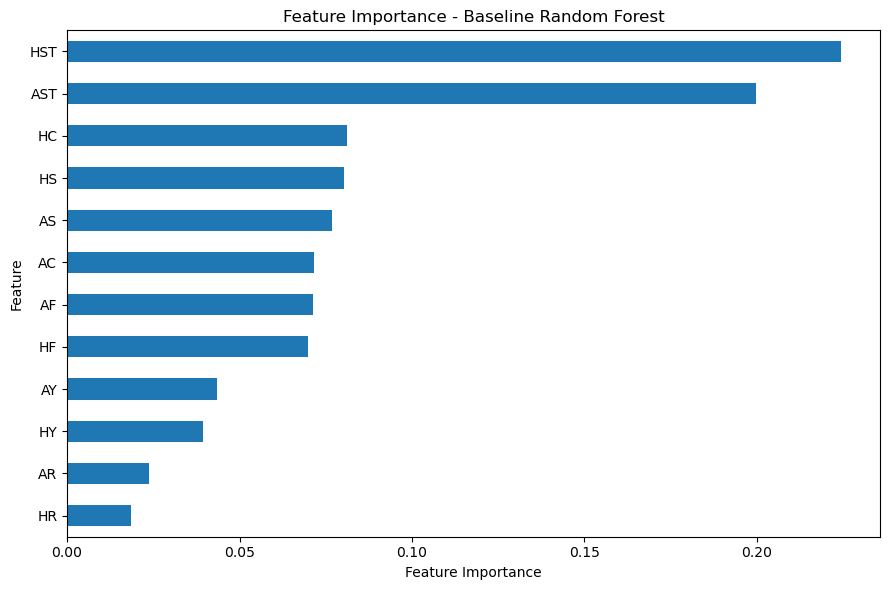

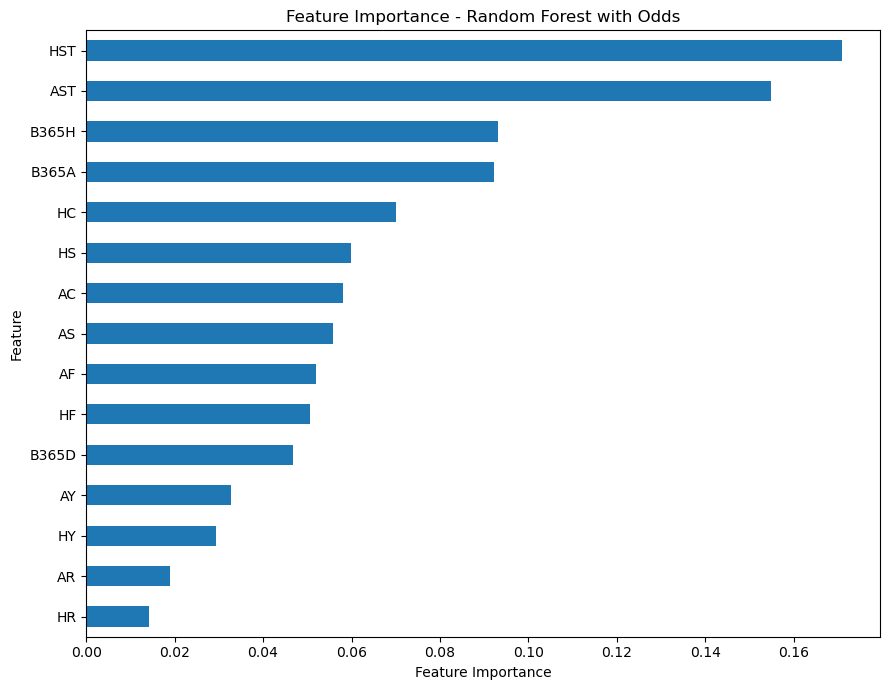

Top 5 features - Baseline RF:


HST    0.2245
AST    0.1997
HC     0.0810
HS     0.0803
AS     0.0768
dtype: float64

Top 5 features - RF with Odds:


HST      0.1710
AST      0.1549
B365H    0.0932
B365A    0.0923
HC       0.0701
dtype: float64

In [30]:

import pandas as pd
import matplotlib.pyplot as plt

# Baseline Random Forest feature importance
importance_baseline = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=True)

# Random Forest with Odds feature importance
importance_odds = pd.Series(
    rf_odds.feature_importances_,
    index=odds_features
).sort_values(ascending=True)

# Baseline plot
fig, ax = plt.subplots(figsize=(9, 6))
importance_baseline.plot.barh(ax=ax)

ax.set_title("Feature Importance - Baseline Random Forest")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

# Odds model plot
fig, ax = plt.subplots(figsize=(9, 7))
importance_odds.plot.barh(ax=ax)

ax.set_title("Feature Importance - Random Forest with Odds")
ax.set_xlabel("Feature Importance")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

# Display top 5 predictors for each model
print("Top 5 features - Baseline RF:")
display(
    importance_baseline.sort_values(
        ascending=False
    ).head(5).round(4)
)

print("Top 5 features - RF with Odds:")
display(
    importance_odds.sort_values(
        ascending=False
    ).head(5).round(4)
)


**Figure interpretation — Feature Importance without Odds.** Home shots on target (HST) and away shots on target (AST) have the highest impurity-based importance scores (about **22.45%** and **19.97%**). Shooting statistics contribute more heavily to the fitted forest than most other individual predictors. These are model-specific importance values, not causal effects. **Figure interpretation — Feature Importance with Odds.** HST and AST remain important (about **17.10%** and **15.49%**), while Bet365 home-win and away-win odds (B365H and B365A) also rank highly (about **9.32%** and **9.23%**). Adding Odds changes the relative importance rankings; correlated features can share importance.

### 7.1 Interpretation of Feature Importance

The feature importance plots compare the relative contributions of match statistics and betting odds in the two Random Forest models. The baseline model uses only full-time match statistics, while the second model also includes Bet365 opening odds. By comparing the rankings, we can investigate whether betting odds become important predictors and whether the relative importance of match statistics changes after adding these features. Feature importance describes associations learned by the models rather than causal effects.

### 7.2 Feature Importance Results

In the baseline Random Forest model, the most important features were home shots on target (HST, 22.45%) and away shots on target (AST, 19.97%). Other important predictors included home corners (HC, 8.10%), home shots (HS, 8.03%) and away shots (AS, 7.68%). In the Random Forest model with betting odds, HST (17.10%) and AST (15.49%) remained the two most important features. However, Bet365 home win odds (B365H, 9.32%) and away win odds (B365A, 9.23%) became the third and fourth most important predictors. These results suggest that betting odds provide additional information alongside full-time match statistics. The relative importance of shots on target decreased after adding odds, partly because importance was redistributed across a larger set of predictors. Overall, shots on target were consistently important in both models, while betting odds also contributed meaningfully to the odds-enhanced model. Feature importance reflects patterns learned by Random Forest rather than causal relationships.

## 8. Discussion

### 8.1 Comparison of Random Forest Models

This study compared six Random Forest experiments trained on Championship, League One and League Two matches and evaluated on Premier League matches.

#### Adding Betting Odds

The original Random Forest used 12 full-time match statistics and achieved 57.21% Accuracy and 45.76% Macro F1. After adding three Bet365 betting odds features, Accuracy increased to 59.61%, an improvement of 2.40 percentage points. Macro F1 also increased to 47.41%. ROC-AUC improved from 0.7134 to 0.7419, while Log Loss decreased from 0.9240 to 0.8839. These results suggest that adding betting odds improved overall classification performance.

#### Class Weight Balancing

The original models struggled to identify drawn matches. After applying `class_weight="balanced"`, Macro F1 increased to 50.24% without odds and 51.63% with odds. Draw Recall also increased from 6.21% to 20.52% without odds, and from 5.14% to 17.69% with odds. However, the balanced models achieved slightly lower overall Accuracy than the original models.

#### Hyperparameter Tuning

GridSearchCV was used to compare 24 parameter combinations using three-fold cross-validation on the lower-league training data. For both the models with and without odds, the best parameters were:

- `n_estimators = 200`
- `max_depth = 12`
- `min_samples_leaf = 3`
- `class_weight = "balanced"`

The tuned model without odds achieved 55.87% Accuracy and 50.47% Macro F1. The tuned model with odds achieved 58.60% Accuracy and 51.99% Macro F1.

#### Overall Model Comparison

| Model | Accuracy (%) | Macro F1 (%) |
|---|---:|---:|
| Original RF | 57.21 | 45.76 |
| Balanced RF | 55.76 | 50.24 |
| Tuned RF | 55.87 | 50.47 |
| Original RF with Odds | 59.61 | 47.41 |
| Balanced RF with Odds | 58.46 | 51.63 |
| Tuned RF with Odds | 58.60 | 51.99 |

The Original RF with Odds achieved the highest Accuracy of 59.61%. However, the Tuned RF with Odds achieved the highest Macro F1 of 51.99%. As our research aims to classify home wins, draws and away wins, Macro F1 is our preferred primary metric because it gives equal importance to all three outcomes. Therefore, the Tuned RF with Odds is preferred among the Random Forest experiments when Macro F1 is prioritised. However, the improvement over the Balanced RF with Odds was small, so further validation would be needed to confirm whether it is consistent across different seasons.

### 8.2 Cross-League Generalisation

The baseline Random Forest achieved a training accuracy of 66.20%, compared with 57.21% on the Premier League test dataset. This difference of 8.99 percentage points suggests that the model does not generalise perfectly from lower-league football to the Premier League. The gap may reflect overfitting, differences in match characteristics, or changes in the distribution of outcomes across leagues. For example, draws represented 27.02% of the lower-league dataset but only 24.70% of Premier League matches. This difference could influence overall accuracy because the model struggles to identify draws.

### 8.3 Class Imbalance and Draw Classification

A major weakness of the baseline model was its low draw recall of 6.21%. To investigate this issue, a class-weighted Random Forest was trained using `class_weight="balanced"`. Draw recall improved from 6.21% to 20.52%, and Draw F1 increased from 10.75% to 25.24%. Macro F1 also improved from 45.76% to 50.24%. However, overall accuracy decreased from 57.21% to 55.76%, while Draw Precision declined from 40.12% to 32.79%. These results demonstrate that improving the identification of drawn matches can involve a trade-off between precision and recall. The class-weighted model provided better balanced performance across the three outcomes, although most draws were still misclassified.

### 8.4 Feature Importance

Shots on target were the most important predictors in both Random Forest models. In the baseline model, HST and AST contributed 22.45% and 19.97% of total feature importance, respectively. After adding odds, B365H and B365A became the third and fourth most important features. These findings suggest that both attacking statistics and betting market information contributed to the models' classifications.

## 9. Limitations

### 9.1 Poor Draw Classification

Both Random Forest models struggled to identify drawn matches. Although class weighting improved draw recall in the baseline model, its recall remained relatively low at 20.52%. Further research could investigate alternative class weights, resampling methods and probability thresholds.

### 9.2 Use of Full-Time Match Statistics

The models use full-time statistics such as shots, corners and fouls. These features are only completely available after a match has finished. Therefore, the models should be interpreted as retrospective match-outcome classifiers rather than genuine pre-match forecasting models. A model intended for pre-match prediction would need to use information available before kick-off, such as opening odds and historical team performance.

### 9.3 Cross-League Differences

The models were trained on lower-league matches and evaluated on Premier League matches. Differences in playing styles, team quality and outcome distributions may affect how well patterns transfer between leagues. This could partly explain the difference between training and test performance.

### 9.4 Model Selection and Validation

The initial Random Forest models used fixed hyperparameters, while later experiments used GridSearchCV with three-fold cross-validation on the lower-league training data to select among a limited set of parameters. The resulting models were evaluated on the Premier League test set, but their performance has not been assessed across multiple independent test seasons. Further testing across seasons and a wider parameter search would strengthen the conclusions.

### 9.5 Missing Data

Complete-case analysis was used because relatively few observations had missing values among the selected predictors. However, removing observations may introduce bias if the missing data are not random. Alternative imputation approaches produced similar results in the baseline Random Forest experiment.

## 10. Conclusion

This project investigated whether Random Forest models trained on lower English football leagues could classify match outcomes in the Premier League. The baseline model used 12 full-time match statistics, while the second model included three additional Bet365 betting odds features. The baseline Random Forest achieved an accuracy of **57.21%**, a Macro F1-score of **45.76%**, and a multiclass ROC-AUC of **0.7134**. Adding betting odds improved accuracy to **59.61%**, Macro F1 to **47.41%**, and multiclass ROC-AUC to **0.7419**. Log Loss also decreased from **0.9240 to 0.8839**. These findings suggest that betting odds provide useful additional information for retrospective match classification. A major limitation was the difficulty of classifying drawn matches. Applying balanced class weights increased draw recall from **6.21% to 20.52%** and Draw F1 from **10.75% to 25.24%**, although overall accuracy decreased slightly. The results also showed an **8.99 percentage-point gap** between baseline training accuracy and Premier League test accuracy, indicating challenges in cross-league generalisation. Overall, Random Forest demonstrated some ability to transfer patterns learned from lower-league football to Premier League match classification, with the odds-enhanced model achieving the best overall performance among the two main models. Future work could focus on class imbalance, hyperparameter optimisation, cross-validation and pre-match feature engineering.

## References

- University of Bristol, Data Science Toolbox <https://dsbristol.github.io/dst/coursebook.html>
- University of Bristol, Linear and Generalised Linear Models (MATH30013) lecture notes

---
### Reproducibility and source notebooks

This standalone Random Forest report retains the full modelling experiments from the integrated project report. The four EDA figures and their explanations are now provided separately in `EDA_Final_Report.ipynb`.

- Run the code cells **from top to bottom** in the repository so `processed-data/football_train_data.csv` and `processed-data/football_test_data.csv` are available.
- The original 12-feature model uses `model`, `X_train_clean`, `X_test`; the 15-feature model uses `rf_odds`, `X_train_odds`, `X_test_odds`.
- GridSearchCV evaluates 24 parameter combinations with three folds for **each** model family and may take time to rerun.
- Existing figure and table outputs are retained from the supplied report. These are **saved outputs**, not evidence that the standalone report was freshly rerun.
- The match-statistic features are available after full-time, so the experiments measure retrospective match classification rather than pre-match forecasting.